# Lesson 6B: Cross-Validation, Tuning & SHAP

Lesson 6 left two open problems:
1. Hyperparameters were **picked by hand**, and models were judged on **one** train/test split, which can be lucky or unlucky.
2. Tree feature importance has **no direction** and can't explain **one specific customer**.

**This notebook fixes both:**
- **Cross-validation (Part A):** a more reliable way to compare models.
- **Hyperparameter tuning (Part B):** let the computer search for good XGBoost settings.
- **SHAP (Part C):** explain *how* each feature pushes churn risk up or down, both overall and for individual customers.
- **Save the final model (Part D)** to disk so the retention platform can use it later.

# Setup

**Imports.** New tools in this lesson:
- `joblib`: saves a trained model to a file and loads it back
- `shap`: explains model predictions
- `StratifiedKFold` and `cross_val_score`: cross-validation
- `RandomizedSearchCV`: automatic hyperparameter search
- `make_pipeline`: chains "scale, then model" into one object (explained in Part A)

Everything else (models and metrics) is the same as in Lessons 5 and 6.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

**Hide a harmless warning from this Mac's math library** (same as in notebook 02).
On macOS, NumPy 2.x uses Apple's *Accelerate* library for matrix multiplication, and it sometimes prints
`RuntimeWarning: divide by zero / overflow encountered in matmul` for perfectly normal numbers (it appears when Logistic Regression trains during cross-validation).
The data has no missing or infinite values and the results are correct, so we hide **only** this specific message.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")

**Load the data and make the same split as every lesson** (`random_state=42`, `stratify=y`).
We also compute the stayed/churned `ratio` (about 2.77) for XGBoost's `scale_pos_weight`, exactly like Lesson 6.

**The test set stays locked away until the very end of Part B.**
All comparing (Part A) and tuning (Part B) happens on the **training set only**.
If we used the test set to choose between models or settings, we would be **"tuning on the exam"**: the final test score would look better than it really is.
That is a form of **data leakage**.

Expected: `(5634, 23) (1409, 23) ratio: 2.77`.

In [3]:
df = pd.read_csv("../data/telco_clean.csv")

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(X_train.shape, X_test.shape, "ratio:", round(ratio, 2))

(5634, 23) (1409, 23) ratio: 2.77


# Part A: Cross-validation

**The problem.** So far we judged each model on **one** train/test split. That's like judging a student on **one exam**: they might get lucky (easy questions) or unlucky (hard questions).
The differences between our models in Lesson 6 were tiny (0.840 vs. 0.842 vs. 0.845), so one lucky or unlucky split could easily flip the ranking.

**The solution: 5-fold cross-validation.**
1. Split the **training data** into 5 equal parts, called **folds**.
2. Train on 4 folds, and test on the 1 fold that was left out.
3. Repeat 5 times, so **every fold is the test fold exactly once**.
4. Report the **average** of the 5 scores (how good the model is) and their **spread**, the **standard deviation** (how much the score jumps around).

```
Round 1: [TEST] [train] [train] [train] [train]
Round 2: [train] [TEST] [train] [train] [train]
Round 3: [train] [train] [TEST] [train] [train]
Round 4: [train] [train] [train] [TEST] [train]
Round 5: [train] [train] [train] [train] [TEST]
Final score: the average of the 5 scores
```

- **Stratified** K-Fold keeps about 26.5% churners in **every** fold (just like `stratify=y` in our train/test split), so no fold is accidentally "easy".
- We use **ROC-AUC** as the score because it measures **ranking quality** and doesn't depend on the 0.5 threshold.
- Note: all of this happens **inside the training set** (5,634 customers). The test set is still untouched.

**Set up the folds.**
- `n_splits=5`: 5 folds
- `shuffle=True`: shuffle the customers before cutting them into folds (in case the file has some order)
- `random_state=42`: the same folds every time we run it, so results are repeatable

We create the `cv` object once and reuse it everywhere, so **every model is tested on exactly the same 5 folds**. That makes the comparison fair.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

**Why Logistic Regression needs a Pipeline here.**
Logistic Regression needs **scaling** (Lesson 5). But inside cross-validation, the "test" fold changes every round.
The scaler must learn its mean/std **only from the 4 training folds** of that round, never from the fold being tested. Otherwise information from the test fold **leaks** into training.

If we scaled `X_train` once before cross-validation, the scaler would already have "seen" every fold, which is leakage.

`make_pipeline(StandardScaler(), LogisticRegression(...))` bundles **"scale, then model"** into **one object**. In every cross-validation round, the pipeline automatically:
1. fits the scaler on the 4 training folds only
2. trains Logistic Regression on the scaled training folds
3. uses that same scaler to only `transform` the test fold, then predicts

**Trees don't need scaling**, so Random Forest and XGBoost don't need a pipeline.

*Note:* this pipeline scales **all** 23 columns, including the 0/1 columns, not just the 3 numeric ones like in Lesson 5. That is harmless: a 0/1 column just becomes two other values (e.g. -0.6 and +1.6), so the information is the same and the model still works correctly.

In [5]:
log_pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))

**Cross-validate the three main models** with exactly the same settings as Lessons 5 and 6.
- `models` is a dictionary that maps each name to its model.
- `cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")` runs the 5 rounds and returns the **5 ROC-AUC scores**.
- `n_jobs=-1` runs the rounds in parallel on all CPU cores (faster).
- We print the mean and std plus the 5 individual fold scores, and collect everything in `cv_table`.

In [6]:
models = {
    "Logistic Regression (balanced)": log_pipe,
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
                             eval_metric="logloss", random_state=42),
}

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name:32}: ROC-AUC = {scores.mean():.3f} ± {scores.std():.3f}   folds: {np.round(scores, 3)}")
    cv_rows.append({"Model": name, "CV ROC-AUC mean": scores.mean(), "CV ROC-AUC std": scores.std()})

cv_table = pd.DataFrame(cv_rows).round(3)
cv_table

Logistic Regression (balanced)  : ROC-AUC = 0.846 ± 0.012   folds: [0.847 0.825 0.841 0.863 0.853]


Random Forest                   : ROC-AUC = 0.846 ± 0.011   folds: [0.842 0.829 0.844 0.856 0.86 ]


XGBoost                         : ROC-AUC = 0.844 ± 0.011   folds: [0.841 0.828 0.842 0.86  0.851]


,Model,CV ROC-AUC mean,CV ROC-AUC std
0,Logistic Regression (balanced),0.846,0.012
1,Random Forest,0.846,0.011
2,XGBoost,0.844,0.011


**How to read the mean and std.**
- **mean**: the model's typical ROC-AUC across the 5 folds. This is a more reliable estimate than one single split.
- **std** (standard deviation): how much the score **jumps around** from fold to fold. The folds above differ by a few hundredths **just because of which customers happen to land in each fold**.

**The honest comparison rule:** if the difference between two models' means is **smaller than their std**, they are basically **tied**. The difference could be pure luck, and a different split might reverse it.

**Plot the cross-validation scores.**
Each bar is the mean ROC-AUC. The black **error bar** (`xerr`) shows plus or minus one standard deviation. If the error bars **overlap a lot**, the models are statistically very close.
`xlim(0.75, 0.90)` zooms in on the interesting range (otherwise all bars would look identical).

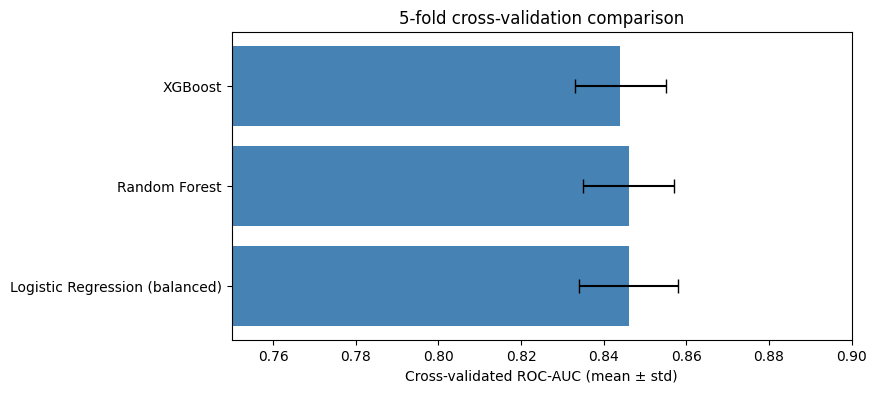

In [7]:
plt.figure(figsize=(8, 4))
plt.barh(cv_table["Model"], cv_table["CV ROC-AUC mean"], xerr=cv_table["CV ROC-AUC std"],
         color="steelblue", capsize=5)
plt.xlim(0.75, 0.90)
plt.xlabel("Cross-validated ROC-AUC (mean ± std)")
plt.title("5-fold cross-validation comparison")
plt.show()

**Our result:** LR (balanced) 0.846 (std 0.012), Random Forest 0.846 (std 0.011), XGBoost 0.844 (std 0.011).
The differences between the three models (at most 0.002) are **much smaller than one standard deviation** (about 0.011), and the error bars overlap almost completely.
So on this data, Logistic Regression (balanced), Random Forest and XGBoost are **essentially tied**. The small differences we saw in Lesson 6 were within the "luck" range of a single split.

# Part B: Hyperparameter tuning (XGBoost)

**Hyperparameters** are the settings **we** choose before training (`max_depth`, `learning_rate`, `n_estimators`, and so on). The model then learns its trees by itself. In Lesson 6 we simply **guessed** them.

**How to search for better settings automatically:**
- **Grid search** tries **every** combination. Our options below have 3 x 4 x 4 x 3 x 3 x 3 = **1,296 combinations**, and with 5 folds that is 6,480 models, which is **slow**.
- **Random search** tries only a **random sample** of combinations (here 20). It is **much faster** and usually finds settings almost as good, because typically only a few settings really matter.

Each combination is scored with **5-fold cross-validation on the training data**, so the **test set is still untouched**.

**Why tune XGBoost?** It has the **most settings** to adjust, so it has the most to gain from tuning. Its hand-picked version in Lesson 6 was slightly *below* Random Forest and Logistic Regression on the test set, so we want to see if better settings help.

**Run the random search.**

The search space (`param_dist`), meaning which values to try for each setting:

| Parameter | Values tried | Meaning |
|---|---|---|
| `n_estimators` | 200, 300, 500 | how many trees to build one after another |
| `max_depth` | 3, 4, 5, 6 | how many questions each tree may ask (deeper = more complex) |
| `learning_rate` | 0.01, 0.03, 0.05, 0.1 | how big a correction each new tree makes (small = careful, needs more trees) |
| `subsample` | 0.7, 0.8, 1.0 | share of customers each tree sees (less than 1.0 adds randomness, which means less overfitting) |
| `colsample_bytree` | 0.7, 0.8, 1.0 | share of features each tree sees (same idea) |
| `min_child_weight` | 1, 3, 5 | **new:** the minimum "amount" of customers needed in a leaf; higher = more **cautious**, so no rules based on very few customers (similar to `min_samples_leaf` in Lesson 6) |

The fixed settings go into `base_xgb`: `scale_pos_weight=ratio` (handles the imbalance), `eval_metric="logloss"`, `random_state=42`.

`RandomizedSearchCV` arguments:
- `n_iter=20`: try 20 random combinations. **20 combinations times 5 folds = 100 models trained.**
- `scoring="roc_auc"`, `cv=cv`: score each combination with the same 5 folds as Part A
- `random_state=42`: the same 20 combinations every run
- `n_jobs=-1`: run in parallel on all CPU cores
- `verbose=1`: print a progress message

After the search, `best_score_` is the best **mean CV ROC-AUC** and `best_params_` is the combination that achieved it.

In [8]:
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

base_xgb = XGBClassifier(scale_pos_weight=ratio, eval_metric="logloss", random_state=42)

search = RandomizedSearchCV(base_xgb,
                            param_distributions=param_dist,
                            n_iter=20,
                            scoring="roc_auc",
                            cv=cv,
                            random_state=42,
                            n_jobs=-1,
                            verbose=1)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 3))
print("Best settings  :", search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Best CV ROC-AUC: 0.849
Best settings  : {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


**How much did tuning help?** We compare the tuned model's CV score with the hand-picked XGBoost from Part A (same 5 folds, so it's a fair comparison).

In [9]:
hand_picked = cv_table.loc[cv_table["Model"] == "XGBoost", "CV ROC-AUC mean"].values[0]

print("Hand-picked XGBoost CV ROC-AUC:", hand_picked)
print("Tuned XGBoost CV ROC-AUC      :", round(search.best_score_, 3))
print("Improvement                   :", round(search.best_score_ - hand_picked, 3))

Hand-picked XGBoost CV ROC-AUC: 0.844
Tuned XGBoost CV ROC-AUC      : 0.849
Improvement                   : 0.005


**Evaluate the tuned model on the test set: the final exam.**
- `search.best_estimator_` is the XGBoost model with the best settings, **already retrained on the full training set** (all 5,634 customers, not just 4 folds). `RandomizedSearchCV` does this automatically at the end (`refit=True` by default).
- **This is the first time the test set is used in this notebook.** We use it **once**, to get an honest final score.
- We compute the same 5 metrics as always, and draw the confusion matrix.

Accuracy : 0.750
Precision: 0.519
Recall   : 0.810
F1       : 0.633
ROC-AUC  : 0.846


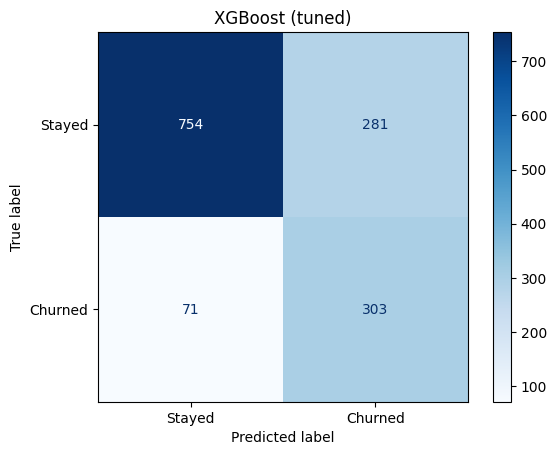

In [10]:
best_xgb = search.best_estimator_

y_pred = best_xgb.predict(X_test)
y_prob = best_xgb.predict_proba(X_test)[:, 1]

tuned_scores = {
    "Model": "XGBoost (tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}
for key, value in tuned_scores.items():
    if key != "Model":
        print(f"{key:9}: {value:.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("XGBoost (tuned)")
plt.show()

**Add the tuned model to the results table, with no duplicates on a re-run.**
First we remove any existing "XGBoost (tuned)" row (it exists if this notebook was already run once), then we add the new row and save.
Expected: **7 rows**.

In [11]:
results = pd.read_csv("../data/model_results.csv")
results = results[results["Model"] != "XGBoost (tuned)"]
results = pd.concat([results, pd.DataFrame([tuned_scores])], ignore_index=True).round(3)
results.to_csv("../data/model_results.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Lazy (predict all stay),0.735,0.000,0.000,0.000,0.500
1,Logistic Regression,0.806,0.658,0.556,0.603,0.842
2,Logistic Regression (balanced),0.740,0.507,0.786,0.616,0.842
3,Decision Tree,0.730,0.495,0.807,0.614,0.830
4,Random Forest,0.762,0.536,0.759,0.628,0.845
5,XGBoost,0.752,0.522,0.783,0.627,0.840
6,XGBoost (tuned),0.750,0.519,0.810,0.633,0.846


## Honest result
Tuning gave only a **small** gain on this dataset: CV ROC-AUC from 0.844 to 0.849 (+0.005), and test ROC-AUC from 0.840 to 0.846.
That gain is **smaller than one CV standard deviation** (about 0.011), so the tuned XGBoost is still essentially tied with Logistic Regression (balanced) and Random Forest. That's normal:
- reasonable settings already capture most of the signal
- the data's main patterns are simple (contract, tenure, internet type, charges)

**Feature quality matters more than tuning.** To make a real jump, we would need *new information* about customers (e.g. usage, complaints, support calls), not just different settings.

# Part C: SHAP explanations

**The problem.** Feature importance (Lesson 6) tells us *how much* a feature matters, but:
- not **in which direction** (does long tenure raise or lower churn?)
- not **for which customer** (why is *this* customer at risk?)

**SHAP** (SHapley Additive exPlanations) comes from **game theory**. Imagine a team wins a prize: Shapley values split the prize **fairly**, based on how much each player contributed.
SHAP does the same for a prediction: the "players" are the **features**, and the "prize" is the model's prediction for one customer.

**For every customer, SHAP gives each feature a number:**
- **positive**: this feature pushes this customer's churn risk **up**
- **negative**: it pushes it **down**
- near 0: it barely matters for this customer

**It adds up exactly:** start from the **average prediction** (over all customers), add all of one customer's SHAP values, and you get **that customer's prediction**.

For XGBoost, SHAP values are in **log-odds**: the model's internal score **before** the sigmoid turns it into a probability (remember Lesson 5). So a SHAP value of +1.0 does **not** mean "+100% risk". For understanding, just read the **direction** (positive or negative) and the **size** (bigger = stronger push).

**Compute SHAP values for every test customer.**
- `shap.TreeExplainer(best_xgb)` is a fast SHAP method designed specifically for tree models.
- `explainer(X_test)` computes the SHAP values. The result has **one value per customer per feature**.

Expected shape: `(1409, 23)`, i.e. 1,409 customers by 23 features.

In [12]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test)
print(shap_values.shape)

(1409, 23)


**Beeswarm plot: global importance *with direction*.**

**How to read it:**
- Each **dot** = one customer (1,409 dots per row).
- **Horizontal position** = the SHAP value: **right** of the centre line means it pushes churn **up**; **left** means it pushes churn **down**.
- **Colour** = that feature's value for that customer: **red = high**, **blue = low**. For 0/1 columns: **red = 1 (Yes)**, **blue = 0 (No)**.
- Rows are sorted **top to bottom by overall importance**.

**What to look for:**
- `tenure`: **blue dots (low tenure) on the right**, so new customers churn more.
- `Contract_Two year` / `Contract_One year`: **red dots (has that contract) on the left**, so long contracts reduce churn.
- `InternetService_Fiber optic`: **red dots on the right**, so fiber increases churn.
- `MonthlyCharges`: red dots (high bills) mostly on the right, so higher bills increase churn.

These match the EDA (Lesson 3) and the LR coefficients (Lesson 5), but now we also see **non-linear detail**: e.g. how *strongly* very low tenure pushes risk up compared with medium tenure.

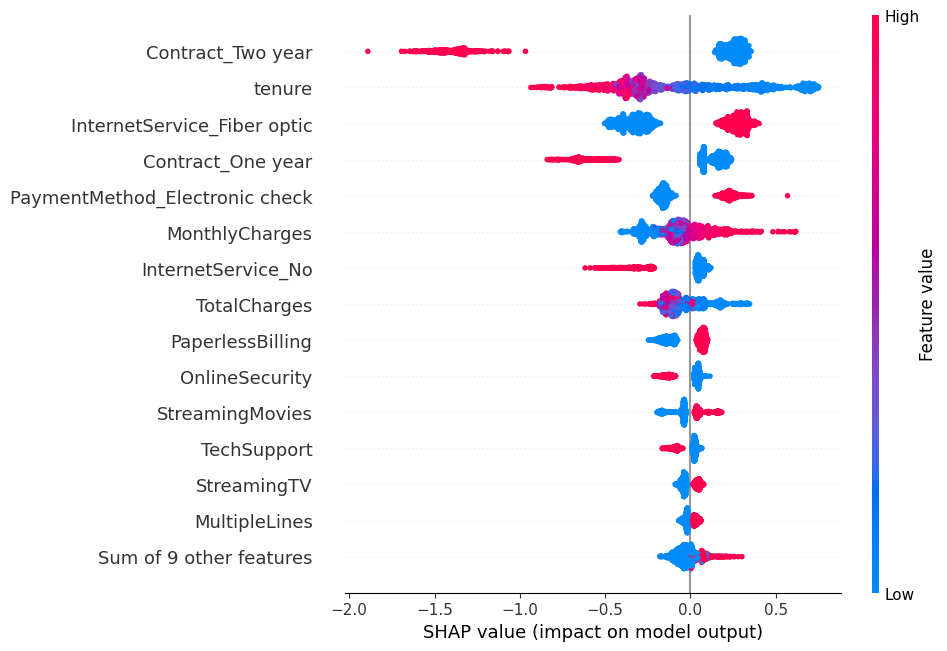

In [13]:
shap.plots.beeswarm(shap_values, max_display=15)

**What our plot shows:**
- **`Contract_Two year`** is the most important feature: having a two-year contract (red) pushes risk strongly **down**, and *not* having one (blue) pushes it **up**.
- **`tenure`**: low tenure (blue) is on the right (**more churn**); long tenure (red) is on the left (**less churn**). As expected.
- **`InternetService_Fiber optic`** and **`PaymentMethod_Electronic check`**: red on the right, so both **increase** churn.
- **`MonthlyCharges`**: very low bills (blue) push risk **down**, and the highest bills (red) push it **up**.
  Notice: in Lesson 5, the Logistic Regression coefficient for MonthlyCharges was *negative* (a side effect of multicollinearity).
  SHAP on XGBoost shows the **intuitive** direction, the one we saw in the EDA (churners pay more).

**Bar plot: overall ranking.**
For each feature, this is the **average absolute SHAP value** (the average size of its push, ignoring direction) over all test customers.
It's a cleaner ranking than `feature_importances_`, because it's based on each feature's **actual impact on the predictions**, not on how often or how usefully it was used for splits inside the trees.

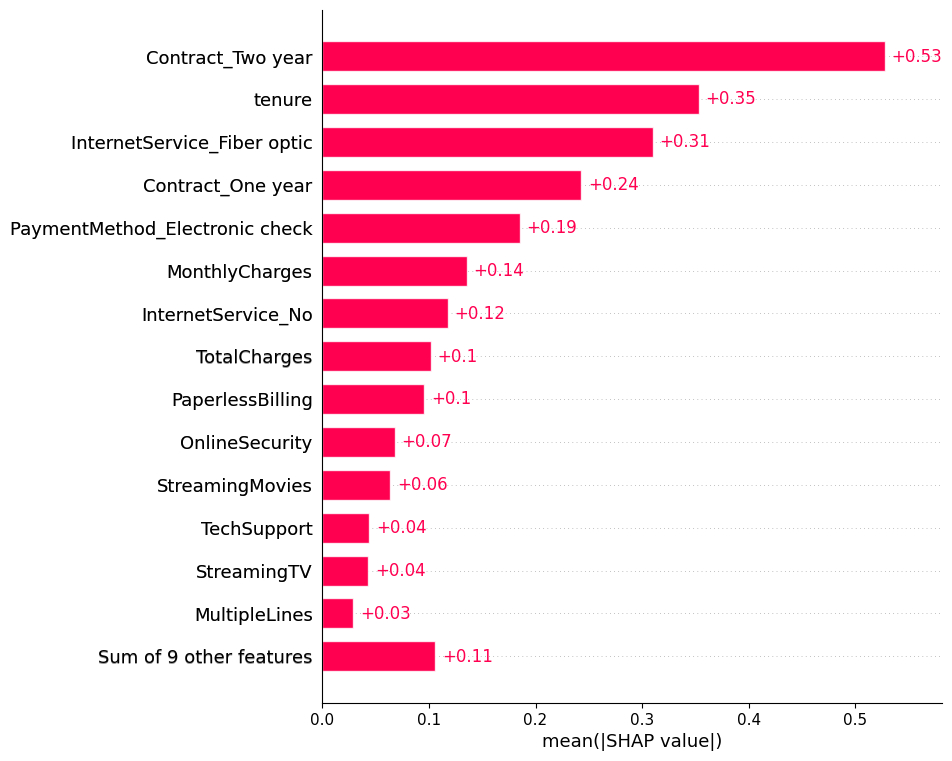

In [14]:
shap.plots.bar(shap_values, max_display=15)

**The same ranking as numbers:** top 5 features by mean |SHAP value|.

In [15]:
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns)
print(mean_abs_shap.sort_values(ascending=False).head(5).round(3))

Contract_Two year                 0.528
tenure                            0.353
InternetService_Fiber optic       0.310
Contract_One year                 0.243
PaymentMethod_Electronic check    0.185
dtype: float32


**Explain one high-risk customer.**
- `probs` = churn probability for every test customer.
- `np.argmax(probs)` finds the **position** of the customer with the **highest** predicted churn risk.
- We print the probability, whether they actually churned, and all their feature values.

**Waterfall plot, how to read it:**
- It starts at the **bottom** with `E[f(X)]`: the **average** model score over all customers (the starting point).
- Each bar is one feature pushing this customer's score **up (red)** or **down (blue)**. The number on the bar is its SHAP value, and the grey text on the left is this customer's value for that feature.
- It ends at the **top** with `f(x)`: **this customer's** final score.
- The remaining small features are grouped into "other features".

**Business use:** this tells a retention agent **why** this customer is at risk (e.g. "month-to-month, 1 month tenure, fiber, no tech support"), so they can choose the **right offer** (e.g. contract discount + free tech support) instead of a random one.

Churn probability: 0.906
Actually churned : 1

gender                                    1.0
SeniorCitizen                             1.0
Partner                                   1.0
Dependents                                0.0
tenure                                    1.0
PhoneService                              1.0
MultipleLines                             1.0
OnlineSecurity                            0.0
OnlineBackup                              0.0
DeviceProtection                          0.0
TechSupport                               0.0
StreamingTV                               1.0
StreamingMovies                           1.0
PaperlessBilling                          1.0
MonthlyCharges                           95.1
TotalCharges                             95.1
InternetService_Fiber optic               1.0
InternetService_No                        0.0
Contract_One year                         0.0
Contract_Two year                         0.0
PaymentMethod_Credit card (automa

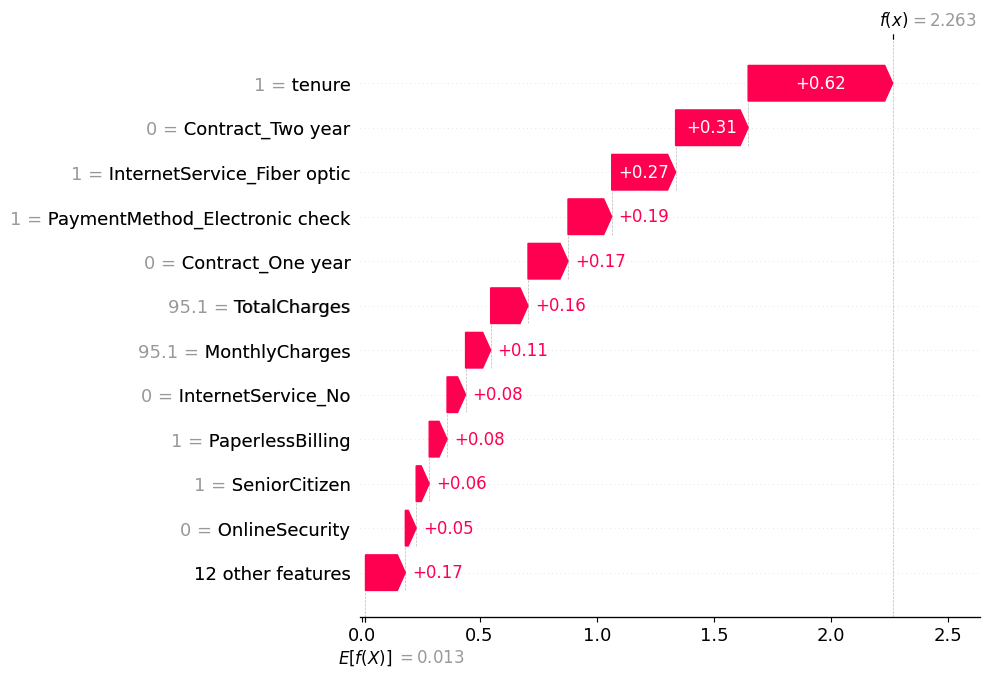

In [16]:
probs = best_xgb.predict_proba(X_test)[:, 1]
high_idx = int(np.argmax(probs))

print("Churn probability:", round(probs[high_idx], 3))
print("Actually churned :", y_test.iloc[high_idx])
print()
print(X_test.iloc[high_idx])

shap.plots.waterfall(shap_values[high_idx], max_display=12)

**The top 3 features pushing this customer's risk up** (as numbers). These are the 3 biggest **positive** SHAP values, i.e. the longest red bars in the waterfall.

In [17]:
high_customer_shap = pd.Series(shap_values.values[high_idx], index=X.columns)
print(high_customer_shap.sort_values(ascending=False).head(3).round(3))

tenure                         0.617
Contract_Two year              0.310
InternetService_Fiber optic    0.273
dtype: float32


**Reading this customer:** they have been a customer for only **1 month**, are on a **month-to-month** contract, use **fiber optic**, pay by **electronic check**, have **no tech support or online security**, and pay about $95/month.
The model gives them about 91% churn risk, and they **really did churn**.

Notice that `Contract_Two year` is one of the top features pushing risk **up**, even though this customer's value is **0**.
SHAP explains the effect of the feature's *value*: here, **not having** a two-year contract pushes the risk up.
So the retention agent could say: "Offer this customer a discounted long-term contract and free tech support."

**Explain one low-risk customer**, the customer with the **lowest** predicted churn risk (`np.argmin`).
Compare this waterfall with the high-risk customer: here the bars should be mostly **blue**, with a **long tenure** and a **two-year contract** pushing the risk strongly **down**.

Churn probability: 0.046
Actually churned : 0

gender                                      0.00
SeniorCitizen                               0.00
Partner                                     1.00
Dependents                                  1.00
tenure                                     71.00
PhoneService                                1.00
MultipleLines                               0.00
OnlineSecurity                              0.00
OnlineBackup                                0.00
DeviceProtection                            0.00
TechSupport                                 0.00
StreamingTV                                 0.00
StreamingMovies                             0.00
PaperlessBilling                            0.00
MonthlyCharges                             19.90
TotalCharges                             1389.35
InternetService_Fiber optic                 0.00
InternetService_No                          1.00
Contract_One year                           0.00
Contract_Two year     

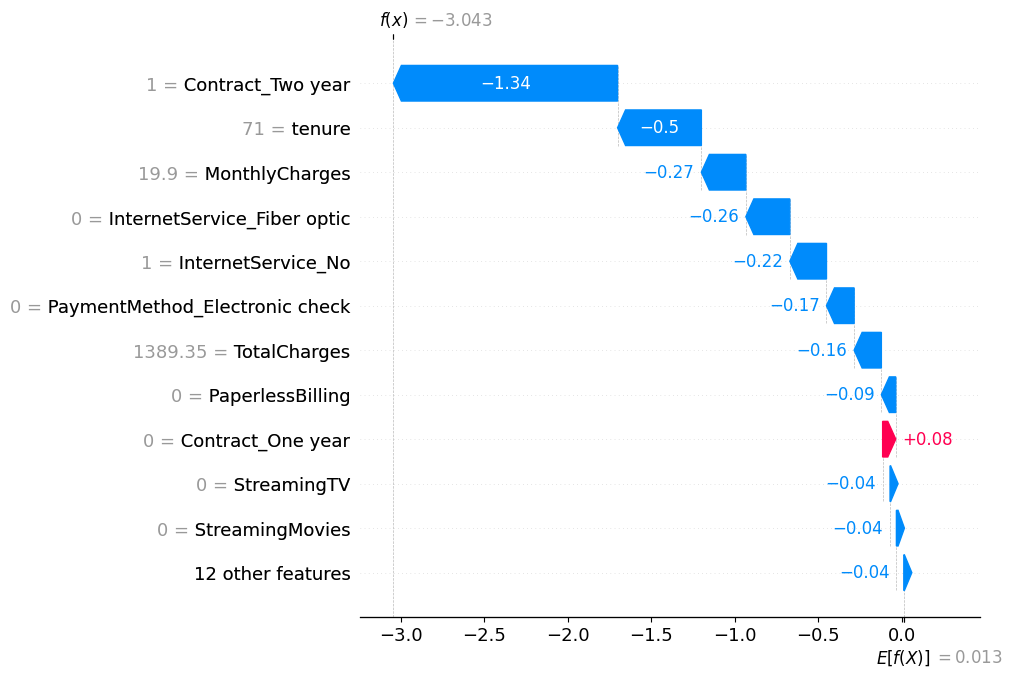

In [18]:
low_idx = int(np.argmin(probs))

print("Churn probability:", round(probs[low_idx], 3))
print("Actually churned :", y_test.iloc[low_idx])
print()
print(X_test.iloc[low_idx])

shap.plots.waterfall(shap_values[low_idx], max_display=12)

**Reading this customer:** **71 months** of tenure, a **two-year contract**, **no internet service**, and a low bill (about $20/month). Their risk is only about 5%, and they **did stay**.
The biggest pushes **down** are `Contract_Two year` and `tenure`, exactly the opposite of the high-risk customer. This is the profile of a loyal customer the company doesn't need to spend retention money on.

# Part D: Save the final model

**Why save the model?** Training takes time. By **saving** the trained model to a file, we never have to retrain it just to make predictions.
The retention platform (API/dashboard, in a later lesson) will simply **load this file** and score new customers.

What this cell does:
1. `os.makedirs("../models", exist_ok=True)` creates the `models/` folder (`exist_ok=True` = no error if it already exists).
2. `joblib.dump(best_xgb, ...)` saves the tuned XGBoost model.
3. We also save the **column order** (`feature_columns.joblib`), because the model expects the 23 features in **exactly the same order** as during training. New data must be arranged the same way.
4. **Reload check:** we load the model back from the file and compute its test ROC-AUC. It must match the score above, which proves the file works.

In [19]:
import os
os.makedirs("../models", exist_ok=True)

joblib.dump(best_xgb, "../models/xgb_tuned.joblib")
joblib.dump(list(X.columns), "../models/feature_columns.joblib")

loaded = joblib.load("../models/xgb_tuned.joblib")
print("Reloaded model ROC-AUC:", round(roc_auc_score(y_test, loaded.predict_proba(X_test)[:, 1]), 3))

Reloaded model ROC-AUC: 0.846


## Findings (Lesson 6B)
1. **5-fold stratified cross-validation** gave a more reliable comparison than one split. LR (balanced) 0.846 (std 0.012), Random Forest 0.846 (std 0.011) and XGBoost 0.844 (std 0.011) ROC-AUC. The differences were **much smaller than one std**, so they're **essentially tied**.
2. For LR, scaling was done **inside a Pipeline**, so the scaler was fit only on the training folds (no leakage).
3. **RandomizedSearchCV** (20 combinations times 5 folds = 100 models) tuned XGBoost: CV ROC-AUC from 0.844 to 0.849. On the test set it reached ROC-AUC 0.846 and recall 0.810 (the best test ROC-AUC so far, but only by a hair). The gain was **small**; feature quality matters more than tuning on this data.
4. The test set was used **only once**, at the end, for the final evaluation.
5. **SHAP** (top 5: Contract_Two year, tenure, Fiber optic, Contract_One year, Electronic check) confirmed the churn drivers **with direction**: low tenure, no long contract (month-to-month), fiber optic and high monthly charges push risk **up**; long tenure and one/two-year contracts push it **down**.
6. SHAP **waterfall plots** explain individual customers, which retention agents need to choose the right offer.
7. The tuned XGBoost model and the column order were saved to `models/` for the retention platform.

## Why move on (Lesson 7)
We've now pushed classical ML about as far as it goes on this data. The next step is **deep learning**: a **neural network (MLP)** on the same data.
The goal is to learn how deep learning works (layers, activation functions, epochs, dropout, early stopping) and to compare it **honestly** with XGBoost on the same test set.